degree is incredibly effective for low seed sizes
Local clustering coef works best with more nodes
Bridge the gap by choosing small number of high degree and then the rest as high clust coef.

In [1]:
import numpy as np
from Influence_Modelling import XsvNetwork, Heuristics, Network, Sampling
import pandas as pd
import matplotlib.pyplot as plt
import math
import scienceplots
plt.style.use(['science', "no-latex"])
import seaborn as sns

air = XsvNetwork.XsvNetwork("airports")
net = Network.Network("")
net.set_nx(Sampling.mhda_sample(air.get_nx(), 1000))
sizes = np.int32(np.round(np.linspace(1, 100, 15)))
sizes

array([  1,   8,  15,  22,  29,  36,  43,  50,  58,  65,  72,  79,  86,
        93, 100], dtype=int32)

In [2]:
def whateverthisis(G, n):
  assert n >= 1
  if n <= 5:
    return Heuristics.deg_h(G, n)
  seeds = set()
  [seeds.add(v) for v in Heuristics.deg_discount_h(G, round(math.log(n)))]
  [seeds.add(v) for v in Heuristics.local_clustering_coefficient_h(G, n - round(math.log(n)))]
  return list(seeds)

def betweenessboogaloo(G, n):
  assert n >= 1
  if n <= 5:
    return Heuristics.deg_h(G, n)
  seeds = set()
  [seeds.add(v) for v in Heuristics.deg_discount_h(G, round(math.log(n)))]
  [seeds.add(v) for v in Heuristics.betweenness_centrality_h(G, n - round(math.log(n)))]
  return list(seeds)

In [3]:
deg = [net.run_ICC(Heuristics.deg_h(net.get_nx(), size)) for size in sizes]
deg = [de[2][-1] for de in deg]

whaterver = [net.run_ICC(whateverthisis(net.get_nx(), size)) for size in sizes]
whaterver = [de[2][-1] for de in whaterver]

#bet = [net.run_ICC(betweenessboogaloo(net.get_nx(), size)) for size in sizes]
#bet = [de[2][-1] for de in bet]

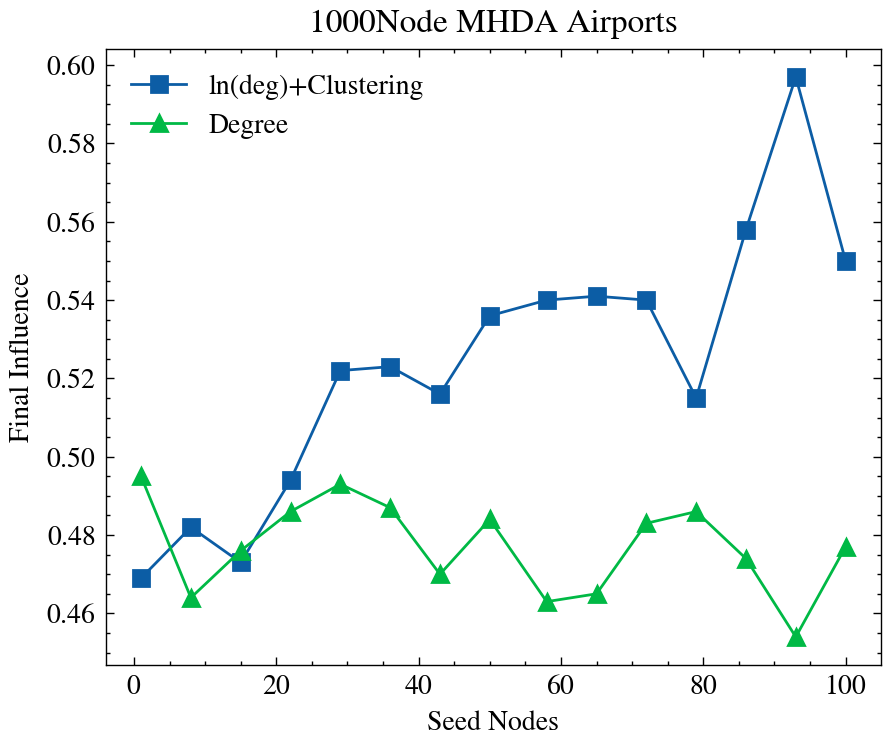

In [4]:
fig, ax = plt.subplots()
fig.set_size_inches(5,4)
fig.set_dpi(200)
ax.plot(sizes, whaterver, label="ln(deg)+Clustering", marker="s")
ax.plot(sizes, deg, label="Degree", marker="^")
#ax.plot(sizes, bet, label="Betweeness Hybrid", marker="o")
ax.set_xlabel("Seed Nodes")
ax.set_ylabel("Final Influence")
ax.set_title("1000Node MHDA Airports")
ax.legend()
#ax.set_xscale("log")

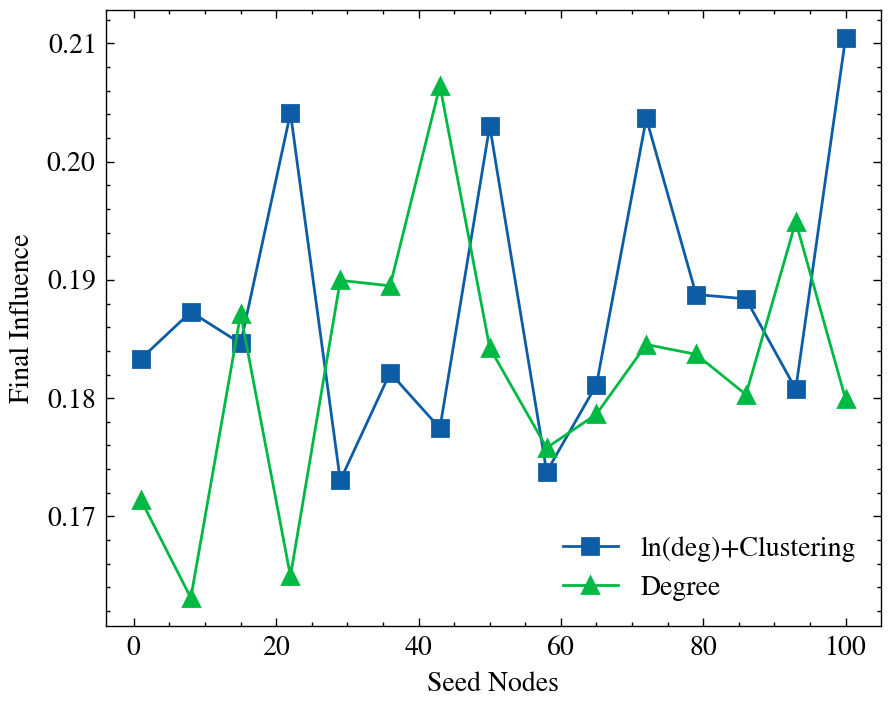

In [5]:
p2p = XsvNetwork.XsvNetwork("p2p")
net = Network.Network("")
#net.set_nx(Sampling.mhda_sample(p2p.get_nx(), 1000))
net.set_nx(p2p.get_nx())
deg = [net.run_ICC(Heuristics.deg_h(net.get_nx(), size)) for size in sizes]
deg = [de[2][-1] for de in deg]
whaterver = [net.run_ICC(whateverthisis(net.get_nx(), size)) for size in sizes]
whaterver = [de[2][-1] for de in whaterver]
#bet = [net.run_ICC(betweenessboogaloo(net.get_nx(), size)) for size in sizes]
#bet = [de[2][-1] for de in bet]

fig, ax = plt.subplots()
fig.set_size_inches(5,4)
fig.set_dpi(200)
ax.plot(sizes, whaterver, label="ln(deg)+Clustering", marker="s")
ax.plot(sizes, deg, label="Degree", marker="^")
#ax.plot(sizes, bet, label="betweenness Hybrid", marker="o")
ax.set_xlabel("Seed Nodes")
ax.set_ylabel("Final Influence")
ax.legend()
#ax.set_xscale("log")

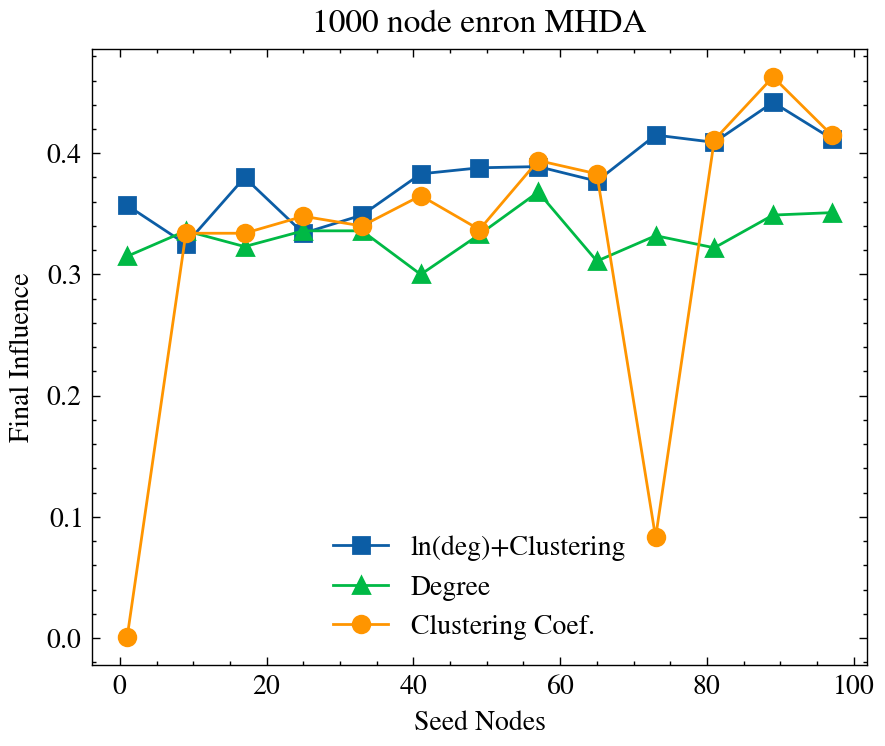

In [35]:
sizes = [x for x in range(1, 100, 8)]
enr = XsvNetwork.XsvNetwork("enron")
net = Network.Network("")
net.set_nx(Sampling.mhda_sample(enr.get_nx(), 1000))
deg = [net.run_ICC(Heuristics.deg_h(net.get_nx(), size)) for size in sizes]
deg = [de[2][-1] for de in deg]

whaterver = [net.run_ICC(whateverthisis(net.get_nx(), size)) for size in sizes]
whaterver = [de[2][-1] for de in whaterver]

bet = [net.run_ICC(Heuristics.local_clustering_coefficient_h(net.get_nx(), size)) for size in sizes]
bet = [de[2][-1] for de in bet]

fig, ax = plt.subplots()
fig.set_size_inches(5,4)
fig.set_dpi(200)
ax.plot(sizes, whaterver, label="ln(deg)+Clustering", marker="s")
ax.plot(sizes, deg, label="Degree", marker="^")
ax.plot(sizes, bet, label="Clustering Coef.", marker="o")
ax.set_xlabel("Seed Nodes")
ax.set_ylabel("Final Influence")
ax.set_title("1000 node enron MHDA")
ax.legend()
#ax.set_xscale("log")

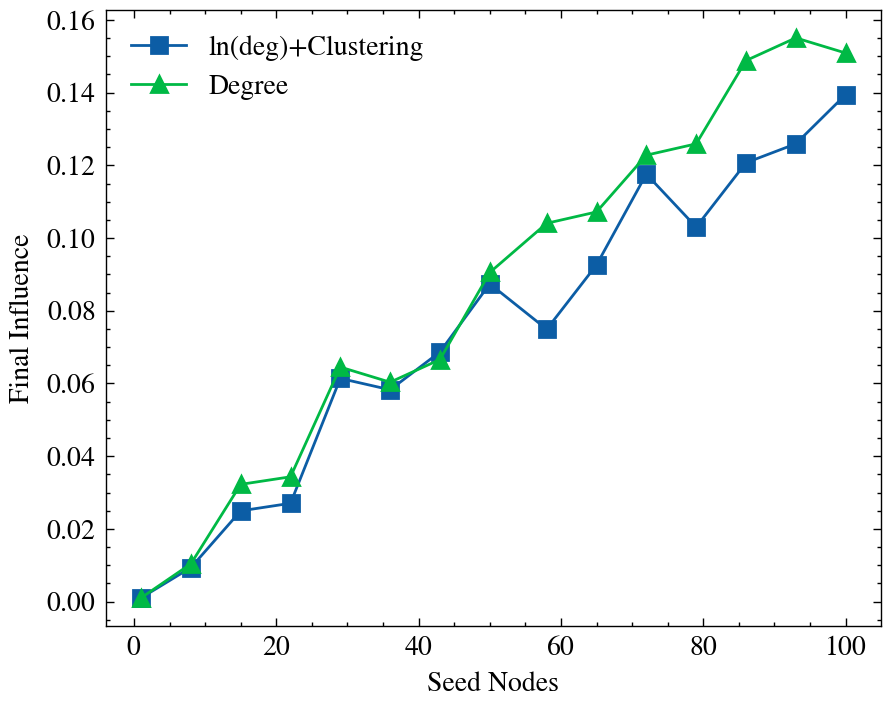

In [7]:
net = Network.Network("")
net.kleinbergs_generator(1000)
deg = [net.run_ICC(Heuristics.deg_h(net.get_nx(), size)) for size in sizes]
deg = [de[2][-1] for de in deg]

whaterver = [net.run_ICC(whateverthisis(net.get_nx(), size)) for size in sizes]
whaterver = [de[2][-1] for de in whaterver]
#bet = [net.run_ICC(betweenessboogaloo(net.get_nx(), size)) for size in sizes]
#bet = [de[2][-1] for de in bet]

fig, ax = plt.subplots()
fig.set_size_inches(5,4)
fig.set_dpi(200)
ax.plot(sizes, whaterver, label="ln(deg)+Clustering", marker="s")
ax.plot(sizes, deg, label="Degree", marker="^")
#ax.plot(sizes, bet, label="betweenness Hybrid", marker="o")
ax.set_xlabel("Seed Nodes")
ax.set_ylabel("Final Influence")
ax.legend()
#ax.set_xscale("log")

NameError: name 'find_overlaps' is not defined

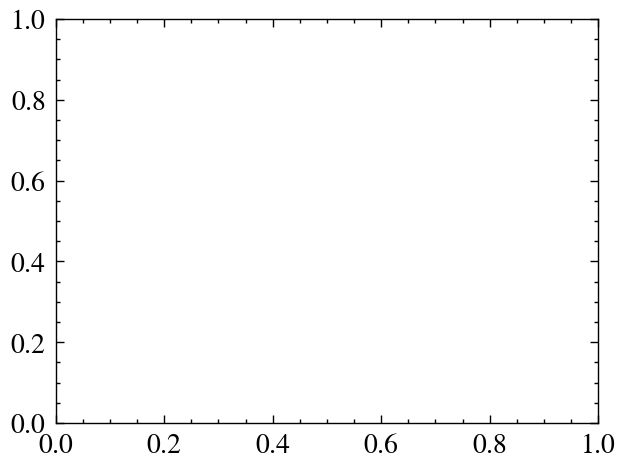

In [8]:
# Why are they the same?
# Highly connected graph with generally even degree distribtion
# Random nodes have the same probability of a long range connection as any other -> no overall structure or stand outs
# leads to sameish choices within random error
fig, ax = plt.subplots()
fig.set_dpi(200)
find_overlaps([Heuristics.deg_h, whateverthisis, Heuristics.deg_discount_h, Heuristics.local_clustering_coefficient_h, betweenessboogaloo], 100, ax, net.get_nx())

In [ ]:
def find_overlaps(methods, size_set, axis, network):
    intersections = {}
    names = []
    for method in methods:
        name = str(method).split(" ")[1]
        names.append(name)
        seeds = set(method(network, size_set))
        intersections[name] = seeds
    abs_matrix = []
    for name in names:
        row = []
        for other_name in names:
            row.append(
                len(
                    list(
                        set.intersection(intersections[name], intersections[other_name])
                    )
                )
            )
        abs_matrix.append(row)
    scaled = np.array(abs_matrix) / size_set
    axis.set_title(f"Proportion of Selected Seed Size Intersecting ({size_set} Nodes)")
    sns.heatmap(scaled, annot=True, ax=axis, cmap="RdYlGn_r", cbar=False, xticklabels=names, yticklabels=names, mask=np.tril(np.ones_like(scaled, dtype=bool), k=-1))
    axis.set_yticklabels(axis.get_yticklabels(), rotation=0)